# Lab 4 — K láng giềng gần nhất (KNN): thực hành

Nguyễn Đình Huy — MSSV: 2474802010140.

Mỗi mục có đúng một cell code. Chọn **Run All** để chạy từ trên xuống. Giữ ba CSV trong `data/`, hoặc tải trực tiếp vào Files trên Colab. Hình lưu trong `figures/`; chạy `scripts/run_all.py` để xuất nhật ký vào `outputs/`.

## 1. Khoảng cách và láng giềng

Theo mục 2.3, `e1_khoang_cach.py`. Giữ cách chuẩn hóa trên toàn bộ dữ liệu để minh họa khoảng cách như mã thầy; đây chưa phải bước đánh giá trên tập kiểm tra.

Khoang cach KHI CHUA chuan hoa
  d(A, B) =    102.2
  d(A, C) =   3000.0

Do lech chuan cua ba cot:
  gio_on 7.82   diem_giua_ky 2.09   chi_tieu 1692

Khoang cach SAU KHI chuan hoa
  d(A, B) = 3.85
  d(A, C) = 1.79

Ban moi: on 12 gio, diem giua ky 6.5
Nam lang gieng gan nhat:
  gio  10.5  diem  6.4  khoang cach 0.198  -> qua
  gio  12.5  diem  6.1  khoang cach 0.202  -> qua
  gio  14.0  diem  6.4  khoang cach 0.260  -> qua
  gio   9.5  diem  6.1  khoang cach 0.373  -> rot
  gio  10.5  diem  5.8  khoang cach 0.386  -> qua
Bo phieu: 4 qua, 1 rot
Du doan: qua mon


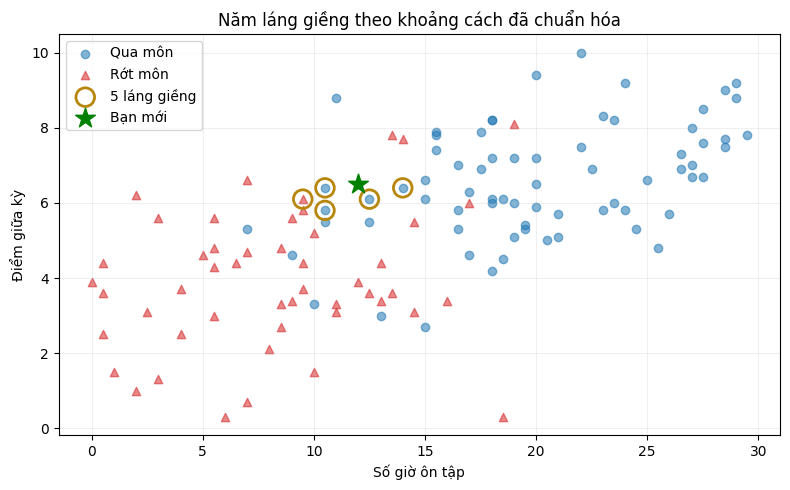

In [1]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd

# Ba bạn: A và C học gần như y hệt nhau, B học khác hẳn.
ba_ban = {
    "A": np.array([5.0, 3.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}

def kc(u, v):
    """Khoang cach Euclid giua hai diem."""
    return np.sqrt(((u - v) ** 2).sum())

print("Khoang cach KHI CHUA chuan hoa")
print(f"  d(A, B) = {kc(ba_ban['A'], ba_ban['B']):8.1f}")
print(f"  d(A, C) = {kc(ba_ban['A'], ba_ban['C']):8.1f}")
print()

# Chuẩn hóa bằng trung bình và độ lệch chuẩn của cả bộ dữ liệu.
df = pd.read_csv(tep_du_lieu("sinh_vien_mo_rong.csv"))
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)
tb = X.mean(axis=0)
dl = X.std(axis=0)
print("Do lech chuan cua ba cot:")
print(f"  gio_on {dl[0]:.2f}   diem_giua_ky {dl[1]:.2f}"
      f"   chi_tieu {dl[2]:.0f}")
print()

chuan = {ten: (v - tb) / dl for ten, v in ba_ban.items()}
print("Khoang cach SAU KHI chuan hoa")
print(f"  d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"  d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")
print()

# Tìm 5 láng giềng của bạn mới, chỉ dùng hai cột học tập.
X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)
ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2
khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]
print("Ban moi: on 12 gio, diem giua ky 6.5")
print("Nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(f"  gio {X2[i, 0]:5.1f}  diem {X2[i, 1]:4.1f}"
          f"  khoang cach {khoang[i]:.3f}  -> {ket}")
so_qua = int(y[gan].sum())
print(f"Bo phieu: {so_qua} qua, {5 - so_qua} rot")
print("Du doan:", "qua mon" if so_qua >= 3 else "rot mon")

# Hình minh họa bổ sung, giữ chung cell của mục này.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
for nhan, ten, mau, marker in [(1, "Qua môn", "tab:blue", "o"), (0, "Rớt môn", "tab:red", "^")]:
    plt.scatter(X2[y == nhan, 0], X2[y == nhan, 1], c=mau, marker=marker, alpha=0.55, label=ten)
plt.scatter(X2[gan, 0], X2[gan, 1], s=180, facecolors="none", edgecolors="darkgoldenrod", linewidths=2, label="5 láng giềng")
plt.scatter(*ban_moi, marker="*", s=220, color="green", label="Bạn mới")
plt.xlabel("Số giờ ôn tập")
plt.ylabel("Điểm giữa kỳ")
plt.title("Năm láng giềng theo khoảng cách đã chuẩn hóa")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "e1_lang_gieng.png", dpi=150)
plt.show()


## 2. Chuẩn hóa dữ liệu

Theo mục 3.2, `e2_chuan_hoa.py`. Pipeline chỉ học trung bình và độ lệch chuẩn từ tập học.

Doan bua ca lop qua         : 0.6000
Ba cot, khong chuan hoa     : 0.5333
Ba cot, co chuan hoa        : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


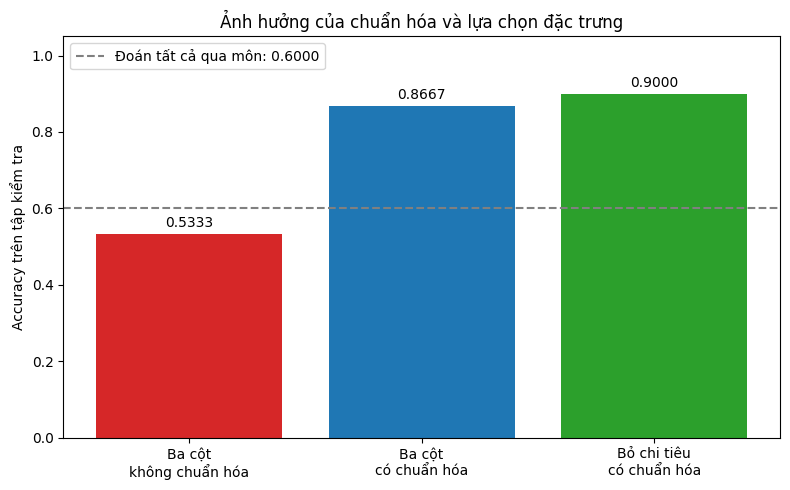

In [2]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(tep_du_lieu("sinh_vien_mo_rong.csv"))
y = df["qua_mon"]
X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)

def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))

def knn_chuan():
    """KNN co chuan hoa, gop lam mot khoi bang pipeline."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(7))

ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]
a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua         : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa     : {a:.4f}")
print(f"Ba cot, co chuan hoa        : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

# Hình minh họa bổ sung, giữ chung cell của mục này.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["Ba cột\nkhông chuẩn hóa", "Ba cột\ncó chuẩn hóa", "Bỏ chi tiêu\ncó chuẩn hóa"], [a, b, c], color=["tab:red", "tab:blue", "tab:green"])
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.axhline(y_te.mean(), color="gray", linestyle="--", label=f"Đoán tất cả qua môn: {y_te.mean():.4f}")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy trên tập kiểm tra")
ax.set_title("Ảnh hưởng của chuẩn hóa và lựa chọn đặc trưng")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "e2_chuan_hoa.png", dpi=150)
plt.show()


## 3. Chọn số láng giềng k

Theo mục 4.2, `e3_chon_k.py`. Bảng điểm tập kiểm tra chỉ dùng minh họa như mã mẫu; k được chọn bằng CV trên tập học, không lấy từ bảng điểm kiểm tra.

Accuracy tren tap hoc va tap kiem tra theo k
   k    tap hoc   tap kiem tra
    1   1.0000     0.8000
    5   0.8756     0.9067
   13   0.8844     0.9200
   31   0.8667     0.8933
  101   0.8311     0.8533

Kiem dinh cheo 5 phan tren tap hoc:


  k =  1  diem trung binh 0.7778
  k =  5  diem trung binh 0.8444
  k =  9  diem trung binh 0.8444
  k = 13  diem trung binh 0.8667  <- tot nhat
  k = 17  diem trung binh 0.8533
  k = 25  diem trung binh 0.8622
  k = 51  diem trung binh 0.8533

k tot nhat = 13
Accuracy tren tap kiem tra = 0.9200


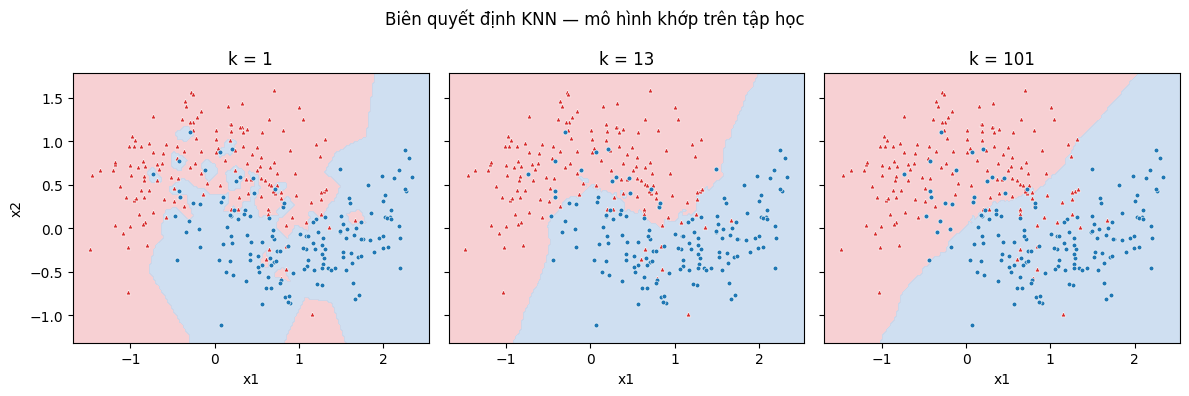

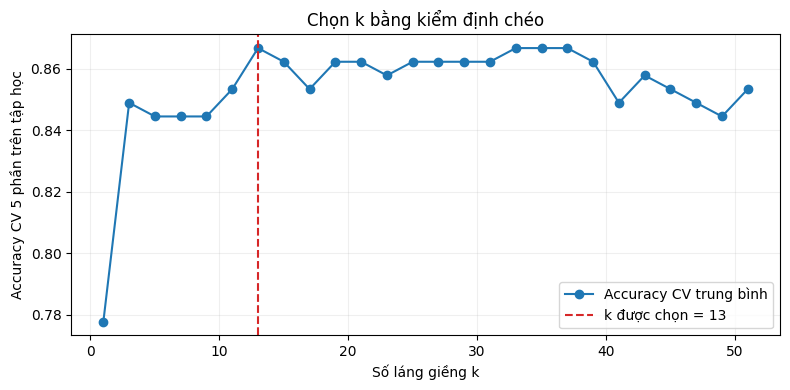

In [3]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai cột có thang đo gần nhau; giữ nguyên cách không chuẩn hóa của thầy.
print("Accuracy tren tap hoc va tap kiem tra theo k")
print("   k    tap hoc   tap kiem tra")
for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {k:3d}   {a_hoc:.4f}     {a_kt:.4f}")
print()

# Chọn k chỉ dựa trên tập học, không nhìn tập kiểm tra.
print("Kiem dinh cheo 5 phan tren tap hoc:")
diem = {}
for k in range(1, 52, 2):
    diem[k] = cross_val_score(KNeighborsClassifier(n_neighbors=k),
                              X_tr, y_tr, cv=5).mean()
k_tot = max(diem, key=diem.get)
for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  diem trung binh {diem[k]:.4f}{dau}")
print()

# Chọn xong mới đánh giá mô hình được chọn trên tập kiểm tra.
mh = KNeighborsClassifier(n_neighbors=k_tot).fit(X_tr, y_tr)
print(f"k tot nhat = {k_tot}")
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

# Hình minh họa bổ sung, giữ chung cell của mục này.
import numpy as np
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X.x1.min() - 0.2, X.x1.max() + 0.2, 180),
                     np.linspace(X.x2.min() - 0.2, X.x2.max() + 0.2, 140))
luoi = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, k in zip(axes, [1, 13, 101]):
    model = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    zz = model.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#f5c5c8", "#c3d8ee"], alpha=0.8)
    for nhan, mau, marker in [(0, "tab:red", "^"), (1, "tab:blue", "o")]:
        ax.scatter(X.loc[y == nhan, "x1"], X.loc[y == nhan, "x2"], s=12, c=mau, marker=marker, edgecolors="white", linewidths=0.4)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("x1")
axes[0].set_ylabel("x2")
fig.suptitle("Biên quyết định KNN — mô hình khớp trên tập học")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "e3_bien_theo_k.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(list(diem), list(diem.values()), "o-", label="Accuracy CV trung bình")
plt.axvline(k_tot, color="tab:red", linestyle="--", label=f"k được chọn = {k_tot}")
plt.xlabel("Số láng giềng k")
plt.ylabel("Accuracy CV 5 phần trên tập học")
plt.title("Chọn k bằng kiểm định chéo")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "e3_chon_k_cv.png", dpi=150)
plt.show()


## 4. So với các mô hình đã học

Theo mục 5, `e4_so_sanh.py`. Cùng dữ liệu hai vầng trăng và cùng phép chia cho cả ba mô hình.

Accuracy tren tap kiem tra, bo hai vang trang
  Hoi quy logistic: 0.8533
  Naive Bayes     : 0.8533
  KNN, k = 13     : 0.9200


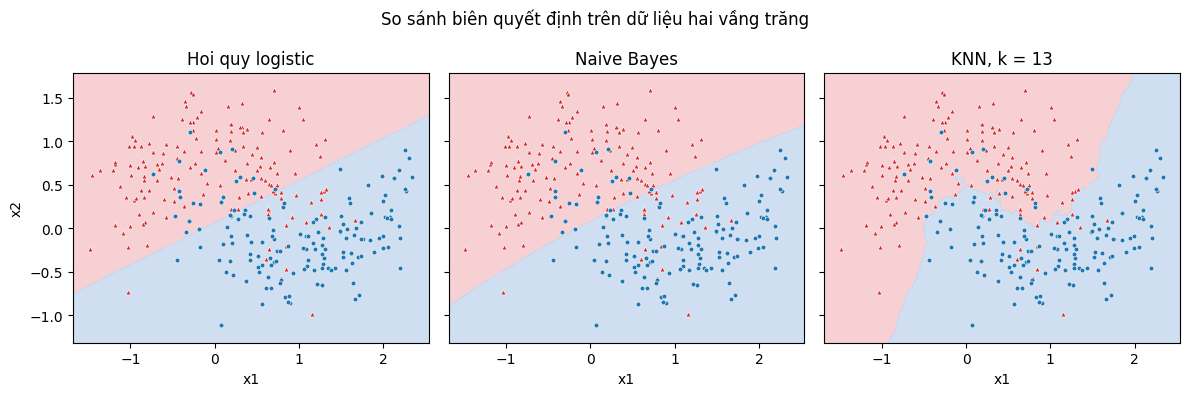

In [4]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes     ", GaussianNB()),
    ("KNN, k = 13     ", KNeighborsClassifier(n_neighbors=13)),
]
print("Accuracy tren tap kiem tra, bo hai vang trang")
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    print(f"  {ten}: {accuracy_score(y_te, mh.predict(X_te)):.4f}")

# Hình minh họa bổ sung, giữ chung cell của mục này.
import numpy as np
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X.x1.min() - 0.2, X.x1.max() + 0.2, 180),
                     np.linspace(X.x2.min() - 0.2, X.x2.max() + 0.2, 140))
luoi = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, (ten, model) in zip(axes, cac_mo_hinh):
    zz = model.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#f5c5c8", "#c3d8ee"], alpha=0.8)
    for nhan, mau, marker in [(0, "tab:red", "^"), (1, "tab:blue", "o")]:
        ax.scatter(X.loc[y == nhan, "x1"], X.loc[y == nhan, "x2"], s=12, c=mau, marker=marker, edgecolors="white", linewidths=0.4)
    ax.set_title(ten.strip())
    ax.set_xlabel("x1")
axes[0].set_ylabel("x2")
fig.suptitle("So sánh biên quyết định trên dữ liệu hai vầng trăng")
fig.tight_layout()
fig.savefig(thu_muc_hinh / "e4_so_sanh.png", dpi=150)
plt.show()


## 5. KNN cho bài toán hồi quy

Theo mục 6, `e5_knn_hoi_quy.py`. So sánh MAE và khả năng dự đoán ngoài miền diện tích đã quan sát.

MAE tren tap kiem tra (ty dong)
  KNN, k = 5 : 0.4030
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich    KNN   duong thang
      60 m2     4.95     5.12
     100 m2     8.32     8.24
     150 m2     9.32    12.13
     250 m2     9.32    19.91

Nam lang gieng cua can 250 m2: 117.5, 115.9, 111.7, 111.2, 104.2


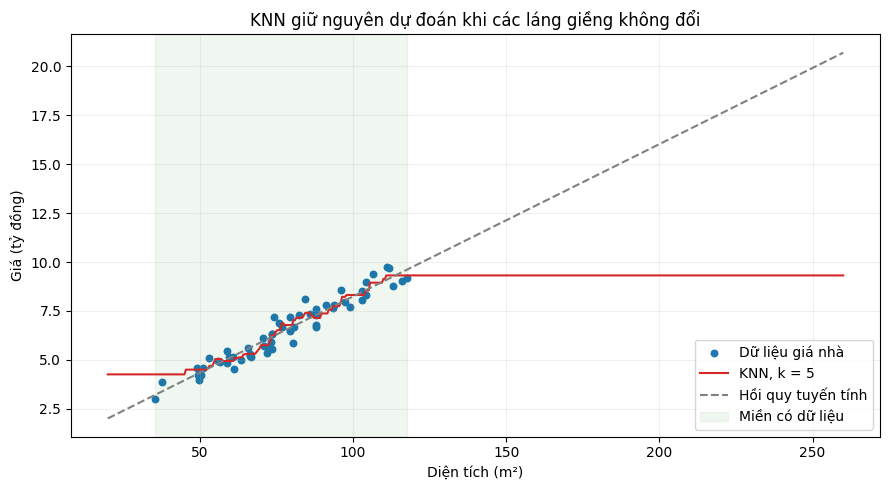

In [5]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv(tep_du_lieu("gia_nha.csv"))
X = df[["dien_tich"]]
y = df["gia"]
# Giữ cùng phép chia với Lab 1.
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

knn = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)
print("MAE tren tap kiem tra (ty dong)")
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  KNN, k = 5 : {mae_knn:.4f}")
print(f"  Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich    KNN   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], knn.predict(can_moi), duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2   {a:6.2f}   {b:6.2f}")
print()

# Năm láng giềng của căn 250 m² chính là những căn rộng nhất đã thấy.
_, chi_so = knn.kneighbors(pd.DataFrame({"dien_tich": [250.0]}))
lg = X_tr.iloc[chi_so[0]]["dien_tich"].tolist()
print("Nam lang gieng cua can 250 m2:", ", ".join(f"{v:.1f}" for v in lg))

# Hình minh họa bổ sung, giữ chung cell của mục này.
import numpy as np
import matplotlib.pyplot as plt

luoi = pd.DataFrame({"dien_tich": np.linspace(20, 260, 500)})
plt.figure(figsize=(9, 5))
plt.scatter(X.dien_tich, y, s=22, label="Dữ liệu giá nhà")
plt.plot(luoi.dien_tich, knn.predict(luoi), color="tab:red", label="KNN, k = 5")
plt.plot(luoi.dien_tich, duong.predict(luoi), "--", color="gray", label="Hồi quy tuyến tính")
plt.axvspan(X.dien_tich.min(), X.dien_tich.max(), color="green", alpha=0.06, label="Miền có dữ liệu")
plt.xlabel("Diện tích (m²)")
plt.ylabel("Giá (tỷ đồng)")
plt.title("KNN giữ nguyên dự đoán khi các láng giềng không đổi")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "e5_hoi_quy.png", dpi=150)
plt.show()
